# Explicit Feedback Neural Recommender Systems

Goals:
- Understand recommender data
- Build different models architectures using Keras
- Retrieve Embeddings and visualize them
- Add metadata information as input to the model

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import os.path as op

from zipfile import ZipFile
try:
    from urllib.request import urlretrieve
except ImportError:
    from urllib import urlretrieve


ML_100K_URL = "http://files.grouplens.org/datasets/movielens/ml-100k.zip"
ML_100K_FILENAME = ML_100K_URL.rsplit('/', 1)[1]
ML_100K_FOLDER = 'ml-100k'

if not op.exists(ML_100K_FILENAME):
    print('Downloading %s to %s...' % (ML_100K_URL, ML_100K_FILENAME))
    urlretrieve(ML_100K_URL, ML_100K_FILENAME)

if not op.exists(ML_100K_FOLDER):
    print('Extracting %s to %s...' % (ML_100K_FILENAME, ML_100K_FOLDER))
    ZipFile(ML_100K_FILENAME).extractall('.')

Extracting ml-100k.zip to ml-100k...


### Ratings file

Each line contains a rated movie:
- a user
- an item
- a rating from 1 to 5 stars

In [2]:
import pandas as pd

raw_ratings = pd.read_csv(op.join(ML_100K_FOLDER, 'u.data'), sep='\t',
                      names=["user_id", "item_id", "rating", "timestamp"])
raw_ratings.head()

,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


### Item metadata file

The item metadata file contains metadata like the name of the movie or the date it was released. The movies file contains columns indicating the movie's genres. Let's only load the first five columns of the file with `usecols`.

In [3]:
m_cols = ['item_id', 'title', 'release_date', 'video_release_date', 'imdb_url']
items = pd.read_csv(op.join(ML_100K_FOLDER, 'u.item'), sep='|',
                    names=m_cols, usecols=range(5), encoding='latin-1')
items

,item_id,title,release_date,video_release_date,imdb_url
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995)
...,...,...,...,...,...
1677,1678,Mat' i syn (1997),06-Feb-1998,NaN,http://us.imdb.com/M/title-exact?Mat%27+i+syn+...
1678,1679,B. Monkey (1998),06-Feb-1998,NaN,http://us.imdb.com/M/title-exact?B%2E+Monkey+(...
1679,1680,Sliding Doors (1998),01-Jan-1998,NaN,http://us.imdb.com/Title?Sliding+Doors+(1998)
1680,1681,You So Crazy (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?You%20So%20Cr...


Let's write a bit of Python preprocessing code to extract the release year as an integer value:

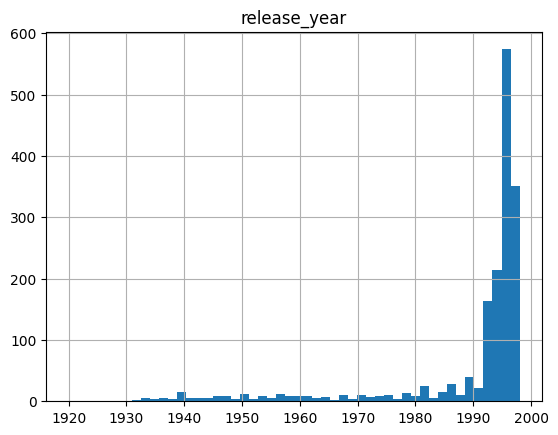

In [4]:
def extract_year(release_date):
    if hasattr(release_date, 'split'):
        components = release_date.split('-')
        if len(components) == 3:
            return int(components[2])
    return 1920


items['release_year'] = items['release_date'].map(extract_year)
items.hist('release_year', bins=50);

Enrich the raw ratings data with the collected items metadata:

In [5]:
all_ratings = pd.merge(items, raw_ratings)

In [6]:
all_ratings.head()

,item_id,title,release_date,video_release_date,imdb_url,release_year,user_id,rating,timestamp
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,308,4,887736532
1,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,287,5,875334088
2,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,148,4,877019411
3,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,280,4,891700426
4,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,66,3,883601324


### Data preprocessing

To understand well the distribution of the data, the following statistics are computed:
- the number of users
- the number of items
- the rating distribution
- the popularity of each movie

In [7]:
min_user_id = all_ratings['user_id'].min()
min_user_id

1

In [8]:
max_user_id = all_ratings['user_id'].max()
max_user_id

943

In [9]:
min_item_id = all_ratings['item_id'].min()
min_item_id

1

In [10]:
max_item_id = all_ratings['item_id'].max()
max_item_id

1682

In [11]:
all_ratings['rating'].describe()

,rating
count,100000.000000
mean,3.529860
std,1.125674
min,1.000000
25%,3.000000
50%,4.000000
75%,4.000000
max,5.000000


Let's do a bit more pandas magic compute the popularity of each movie (number of ratings):

In [12]:
popularity = all_ratings.groupby('item_id').size().reset_index(name='popularity')
items = pd.merge(popularity, items)

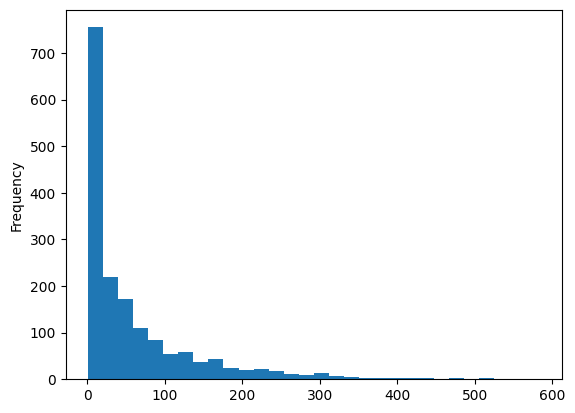

In [13]:
items['popularity'].plot.hist(bins=30);

In [14]:
(items['popularity'] == 1).sum()

np.int64(141)

In [15]:
items.nlargest(10, 'popularity')

,item_id,popularity,title,release_date,video_release_date,imdb_url,release_year
49,50,583,Star Wars (1977),01-Jan-1977,NaN,http://us.imdb.com/M/title-exact?Star%20Wars%2...,1977
257,258,509,Contact (1997),11-Jul-1997,NaN,http://us.imdb.com/Title?Contact+(1997/I),1997
99,100,508,Fargo (1996),14-Feb-1997,NaN,http://us.imdb.com/M/title-exact?Fargo%20(1996),1997
180,181,507,Return of the Jedi (1983),14-Mar-1997,NaN,http://us.imdb.com/M/title-exact?Return%20of%2...,1997
293,294,485,Liar Liar (1997),21-Mar-1997,NaN,http://us.imdb.com/Title?Liar+Liar+(1997),1997
285,286,481,"English Patient, The (1996)",15-Nov-1996,NaN,http://us.imdb.com/M/title-exact?English%20Pat...,1996
287,288,478,Scream (1996),20-Dec-1996,NaN,http://us.imdb.com/M/title-exact?Scream%20(1996),1996
0,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995
299,300,431,Air Force One (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Air+Force+One...,1997
120,121,429,Independence Day (ID4) (1996),03-Jul-1996,NaN,http://us.imdb.com/M/title-exact?Independence%...,1996


In [16]:
items["title"][181]

'GoodFellas (1990)'

In [17]:
items["title"].loc[181]

'GoodFellas (1990)'

In [18]:
items["title"].iloc[181]

'GoodFellas (1990)'

In [19]:
indexed_items = items.set_index('item_id')
indexed_items.nlargest(10, 'popularity')

,popularity,title,release_date,video_release_date,imdb_url,release_year
item_id,,,,,,
50,583,Star Wars (1977),01-Jan-1977,NaN,http://us.imdb.com/M/title-exact?Star%20Wars%2...,1977
258,509,Contact (1997),11-Jul-1997,NaN,http://us.imdb.com/Title?Contact+(1997/I),1997
100,508,Fargo (1996),14-Feb-1997,NaN,http://us.imdb.com/M/title-exact?Fargo%20(1996),1997
181,507,Return of the Jedi (1983),14-Mar-1997,NaN,http://us.imdb.com/M/title-exact?Return%20of%2...,1997
294,485,Liar Liar (1997),21-Mar-1997,NaN,http://us.imdb.com/Title?Liar+Liar+(1997),1997
286,481,"English Patient, The (1996)",15-Nov-1996,NaN,http://us.imdb.com/M/title-exact?English%20Pat...,1996
288,478,Scream (1996),20-Dec-1996,NaN,http://us.imdb.com/M/title-exact?Scream%20(1996),1996
1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995
300,431,Air Force One (1997),01-Jan-1997,NaN,http://us.imdb.com/M/title-exact?Air+Force+One...,1997


In [20]:
indexed_items["title"][181]

'Return of the Jedi (1983)'

In [21]:
indexed_items["title"].loc[181]

'Return of the Jedi (1983)'

In [22]:
indexed_items["title"].iloc[181]

'GoodFellas (1990)'

In [23]:
all_ratings = pd.merge(popularity, all_ratings)
all_ratings.describe()

,item_id,popularity,video_release_date,release_year,user_id,rating,timestamp
count,100000.000000,100000.000000,0.0,100000.000000,100000.00000,100000.000000,1.000000e+05
mean,425.530130,168.071900,NaN,1987.950100,462.48475,3.529860,8.835289e+08
std,330.798356,121.784558,NaN,14.169558,266.61442,1.125674,5.343856e+06
min,1.000000,1.000000,NaN,1920.000000,1.00000,1.000000,8.747247e+08
25%,175.000000,71.000000,NaN,1986.000000,254.00000,3.000000,8.794487e+08
50%,322.000000,145.000000,NaN,1994.000000,447.00000,4.000000,8.828269e+08
75%,631.000000,239.000000,NaN,1996.000000,682.00000,4.000000,8.882600e+08
max,1682.000000,583.000000,NaN,1998.000000,943.00000,5.000000,8.932866e+08


In [24]:
all_ratings.head()

,item_id,popularity,title,release_date,video_release_date,imdb_url,release_year,user_id,rating,timestamp
0,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,308,4,887736532
1,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,287,5,875334088
2,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,148,4,877019411
3,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,280,4,891700426
4,1,452,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995,66,3,883601324


Later in the analysis we will assume that this popularity does not come from the ratings themselves but from an external metadata, e.g. box office numbers in the month after the release in movie theaters.

Let's split the enriched data in a train / test split to make it possible to do predictive modeling:

In [25]:
from sklearn.model_selection import train_test_split

ratings_train, ratings_test = train_test_split(
    all_ratings, test_size=0.2, random_state=0)

user_id_train = np.array(ratings_train['user_id'])
item_id_train = np.array(ratings_train['item_id'])
rating_train = np.array(ratings_train['rating'])

user_id_test = np.array(ratings_test['user_id'])
item_id_test = np.array(ratings_test['item_id'])
rating_test = np.array(ratings_test['rating'])

# Explicit feedback: supervised ratings prediction

For each pair of (user, item) try to predict the rating the user would give to the item.

This is the classical setup for building recommender systems from offline data with explicit supervision signal.

## Predictive ratings  as a regression problem

The following code implements the following architecture:

<img src="images/rec_archi_1.svg" style="width: 600px;" />

In [26]:
from keras.layers import Embedding, Flatten, Dense, Dropout
from keras.layers import Dot
from keras.models import Model

In [27]:
class RegressionModel(Model):
    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_user_id + 1,
                                        input_length=1,
                                        name='user_embedding')
        self.item_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_item_id + 1,
                                        input_length=1,
                                        name='item_embedding')

        # The following two layers don't have parameters.
        self.flatten = Flatten()
        self.dot = Dot(axes=1)

    def call(self, inputs):
        user_inputs = inputs[0]
        item_inputs = inputs[1]

        user_vecs = self.flatten(self.user_embedding(user_inputs))
        item_vecs = self.flatten(self.item_embedding(item_inputs))

        y = self.dot([user_vecs, item_vecs])
        return y


model = RegressionModel(64, max_user_id, max_item_id)
model.compile(optimizer="adam", loss='mae')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [28]:
initial_train_preds = model.predict([user_id_train, item_id_train])
initial_train_preds.shape

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step


(80000, 1)

### Model error

Using `initial_train_preds`, compute the model errors:
- mean absolute error
- mean squared error

Converting a pandas Series to numpy array is usually implicit, but you may use `rating_train.values` to do so explicitly. Be sure to monitor the shapes of each object you deal with by using `object.shape`.

In [57]:
# Verify your answer from a tutor.
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("The MAE is:", mean_absolute_error(initial_train_preds, rating_train))
print("The MSE is:", mean_squared_error(initial_train_preds, rating_train))

The MAE is: 3.5285563468933105
The MSE is: 13.719354629516602


### Monitoring runs

Keras enables to monitor various variables during training.

`history.history` returned by the `model.fit` function is a dictionary
containing the `'loss'` and validation loss `'val_loss'` after each epoch

In [58]:
%%time

# Training the model
history = model.fit([user_id_train, item_id_train], rating_train,
                    batch_size=64, epochs=10, validation_split=0.1,
                    shuffle=True)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 2.5988 - val_loss: 1.0244
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.8463 - val_loss: 0.7946
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7558 - val_loss: 0.7664
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7318 - val_loss: 0.7589
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.7130 - val_loss: 0.7534
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6955 - val_loss: 0.7463
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.6759 - val_loss: 0.7438
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6560 - val_loss: 0.7441
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6333 - val_loss: 0.7374
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.6084 - val_loss: 0.7426
CPU times: user 46.4 s, sys: 2.98 s, total: 49.4 s
Wall time: 45.9 s


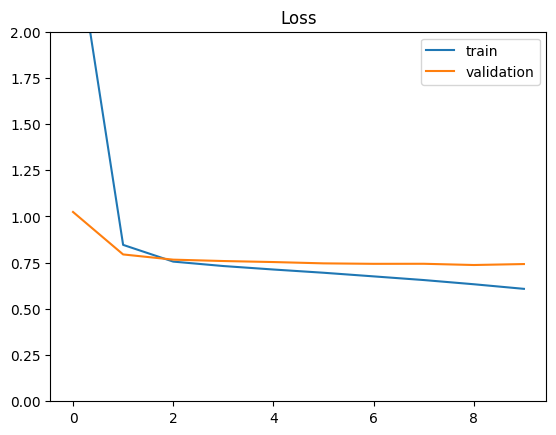

In [59]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.ylim(0, 2)
plt.legend(loc='best')
plt.title('Loss');

**Questions**:

- Why is the train loss higher than the first loss in the first few epochs?

-> Because the initial loss is calculated before training using the model's initial weights. During training the model updates its weights after each batch using gradient descent.
The training loss at the end of an epoch is averaged across batches, where the model's weights change after each batch.

- Why is Keras not computing the train loss on the full training set at the end of each epoch as it does on the validation set?

-> Since Keras calculates training loss batch by batch while updating the model's weights. It will aggregate the batch losses to give the epoch's training loss.
For validation, Keras will evaluate the model on the validation set after the epoch finishes without updating the weights. This means the validation loss is calculated using the same final weights for all validation batches.
Recalculating training loss over the entire training set after every epoch would need one more forward pass so it increases computation time.


Now that the model is trained, the model MSE and MAE look nicer:

In [60]:
def plot_predictions(y_true, y_pred):
    plt.figure(figsize=(4, 4))
    plt.xlim(-1, 6)
    plt.xlabel("True rating")
    plt.ylim(-1, 6)
    plt.ylabel("Predicted rating")
    plt.scatter(y_true, y_pred, s=60, alpha=0.01)

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Final test MSE: 0.902
Final test MAE: 0.732


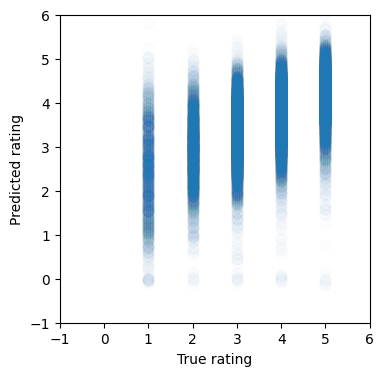

In [61]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

test_preds = model.predict([user_id_test, item_id_test])
print("Final test MSE: %0.3f" % mean_squared_error(test_preds, rating_test))
print("Final test MAE: %0.3f" % mean_absolute_error(test_preds, rating_test))
plot_predictions(rating_test, test_preds)

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Final train MSE: 0.643
Final train MAE: 0.588


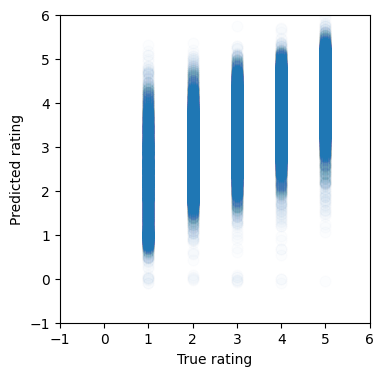

In [62]:
train_preds = model.predict([user_id_train, item_id_train])
print("Final train MSE: %0.3f" % mean_squared_error(train_preds, rating_train))
print("Final train MAE: %0.3f" % mean_absolute_error(train_preds, rating_train))
plot_predictions(rating_train, train_preds)

### Model Embeddings

- It is possible to retrieve the embeddings by simply using the Keras function `model.get_weights` which returns all the model learnable parameters.
- The weights are returned the same order as they were build in the model
- What is the total number of parameters?

In [63]:
# weights and shape
weights = model.get_weights()
[w.shape for w in weights]

[(944, 64), (1683, 64)]

In [64]:
# Solution:
model.summary()

Model: "regression_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ user_embedding (Embedding)      │ (32, 64)               │        60,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ item_embedding (Embedding)      │ (32, 64)               │       107,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dot (Dot)                       │ (32, 1)                │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504,386 (1.92 MB)

 Trainable params: 168,128 (656.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 336,258 (1.28 MB)

In [65]:
user_embeddings = weights[0]
item_embeddings = weights[1]

In [66]:
item_id = 181
print(f"Title for item_id={item_id}: {indexed_items['title'][item_id]}")

Title for item_id=181: Return of the Jedi (1983)


In [67]:
print(f"Embedding vector for item_id={item_id}")
print(item_embeddings[item_id])
print("shape:", item_embeddings[item_id].shape)

Embedding vector for item_id=181
[-0.42744756 -0.1271506  -0.14572646  0.37235236 -0.26501694 -0.03512611
  0.4876697  -0.11460506 -0.35652333  0.39669886 -0.2774068   0.23453203
 -0.09627994  0.19911347  0.11498865  0.15592194  0.37552977 -0.14202781
 -0.1897559   0.14384025  0.37206048  0.4052401  -0.00798112 -0.47108722
  0.27616042  0.53986186  0.4672559   0.02442015  0.19660412  0.46012053
 -0.00137689  0.35696426 -0.42922166  0.28922147 -0.41794488 -0.39213684
  0.34057206 -0.41970292  0.36436772 -0.14692369 -0.30997622 -0.12685136
 -0.28089994 -0.21277413  0.32179213 -0.42225814 -0.28793845  0.35247037
  0.8488287   0.15871759 -0.16664276  0.21839903  0.48131552  0.30444717
 -0.20620504 -0.30324242 -0.03333687  0.23133601 -0.3319031   0.54688746
  0.37848684  0.25614285 -0.48359028 -0.3878501 ]
shape: (64,)


### Finding most similar items

Finding k most similar items to a point in embedding space

- Write in numpy a function to compute the cosine similarity between two points in embedding space.
- Test it on the following cells to check the similarities between popular movies.
- Bonus: try to generalize the function to compute the similarities between one movie and all the others and return the most related movies.

Notes:
- you may use `np.linalg.norm` to compute the norm of vector, and you may specify the `axis=`
- the numpy function `np.argsort(...)` enables to compute the sorted indices of a vector
- `items["name"][idxs]` returns the names of the items indexed by array idxs

In [30]:
EPSILON = 1e-07  # to avoid division by 0.


def cosine(x, y):
    # Calculate cosine similarity between 2 vectors
    return np.dot(x, y) / (
        np.linalg.norm(x) * np.linalg.norm(y) + EPSILON
    )

In [85]:
# Verify your answer from a tutor.

# calculate similarity between item 50 and all items
similarities = np.dot(item_embeddings, item_embeddings[50]) / (
    np.linalg.norm(item_embeddings, axis=1)
    * np.linalg.norm(item_embeddings[50]) + EPSILON
)

# sort indices from highest to lowest similarity
idxs = np.argsort(similarities)[::-1]

# filter out 0 since it is the padding index and not a real movie ID
idxs = [idx for idx in idxs if idx in indexed_items.index]

print(indexed_items["title"].loc[idxs])

item_id
50                     Star Wars (1977)
172     Empire Strikes Back, The (1980)
181           Return of the Jedi (1983)
174      Raiders of the Lost Ark (1981)
173          Princess Bride, The (1987)
                     ...               
1650            Butcher Boy, The (1998)
1675              Sunchaser, The (1996)
1491            Tough and Deadly (1995)
1584     Symphonie pastorale, La (1946)
1616                Desert Winds (1995)
Name: title, Length: 1682, dtype: object


In [36]:
# Get movie embeddings from trained model
item_embeddings = model.get_weights()[1]

In [37]:
def print_similarity(item_a, item_b, item_embeddings, titles):
    print(titles[item_a])
    print(titles[item_b])
    similarity = cosine(item_embeddings[item_a],
                        item_embeddings[item_b])
    print(f"Cosine similarity: {similarity:.3}")

print_similarity(50, 181, item_embeddings, indexed_items["title"])

Star Wars (1977)
Return of the Jedi (1983)
Cosine similarity: 0.053


In [38]:
print_similarity(181, 288, item_embeddings, indexed_items["title"])

Return of the Jedi (1983)
Scream (1996)
Cosine similarity: 0.0664


In [39]:
print_similarity(181, 1, item_embeddings, indexed_items["title"])

Return of the Jedi (1983)
Toy Story (1995)
Cosine similarity: 0.0729


In [40]:
print_similarity(181, 181, item_embeddings, indexed_items["title"])

Return of the Jedi (1983)
Return of the Jedi (1983)
Cosine similarity: 1.0


In [41]:
def cosine_similarities(item_id, item_embeddings):
    """Compute similarities between item_id and all items embeddings"""
    query_vector = item_embeddings[item_id]
    dot_products = item_embeddings @ query_vector

    query_vector_norm = np.linalg.norm(query_vector)
    all_item_norms = np.linalg.norm(item_embeddings, axis=1)
    norm_products = query_vector_norm * all_item_norms
    return dot_products / (norm_products + EPSILON)


similarities = cosine_similarities(181, item_embeddings)
similarities

array([-0.06693905,  0.07285407,  0.28241953, ...,  0.17132615,
        0.01052835,  0.13944314], dtype=float32)

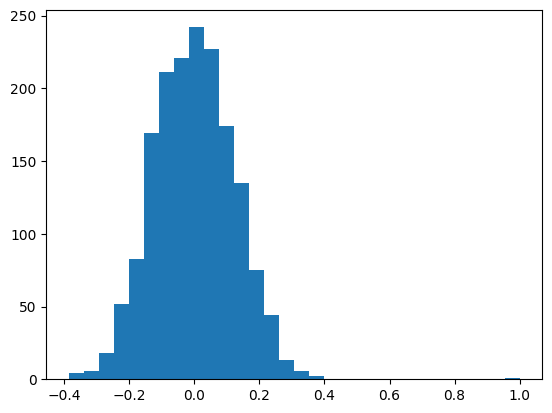

In [42]:
plt.hist(similarities, bins=30);

In [43]:
def most_similar(item_id, item_embeddings, titles,
                 top_n=30):
    sims = cosine_similarities(item_id, item_embeddings)
    # [::-1] makes it possible to reverse the order of a numpy
    # array, this is required because most similar items have
    # a larger cosine similarity value
    sorted_indexes = np.argsort(sims)[::-1]
    idxs = sorted_indexes[0:top_n]
    return list(zip(idxs, titles[idxs], sims[idxs]))


most_similar(50, item_embeddings, indexed_items["title"], top_n=10)

[(np.int64(50), 'Star Wars (1977)', np.float32(0.99999833)),
 (np.int64(1315), 'Inventing the Abbotts (1997)', np.float32(0.47800013)),
 (np.int64(1633),
  'Á köldum klaka (Cold Fever) (1994)',
  np.float32(0.44300592)),
 (np.int64(268), 'Chasing Amy (1997)', np.float32(0.43743128)),
 (np.int64(1299), 'Penny Serenade (1941)', np.float32(0.38752562)),
 (np.int64(1427), 'Drunks (1995)', np.float32(0.36282757)),
 (np.int64(1613), 'Tokyo Fist (1995)', np.float32(0.351893)),
 (np.int64(659), 'Arsenic and Old Lace (1944)', np.float32(0.33936092)),
 (np.int64(1038), 'Switchback (1997)', np.float32(0.32987624)),
 (np.int64(984), 'Shadow Conspiracy (1997)', np.float32(0.32740423))]

In [44]:
items[items['title'].str.contains("Star Trek")]

,item_id,popularity,title,release_date,video_release_date,imdb_url,release_year
221,222,365,Star Trek: First Contact (1996),22-Nov-1996,NaN,http://us.imdb.com/M/title-exact?Star%20Trek:%...,1996
226,227,161,Star Trek VI: The Undiscovered Country (1991),01-Jan-1991,NaN,http://us.imdb.com/M/title-exact?Star%20Trek%2...,1991
227,228,244,Star Trek: The Wrath of Khan (1982),01-Jan-1982,NaN,http://us.imdb.com/M/title-exact?Star%20Trek:%...,1982
228,229,171,Star Trek III: The Search for Spock (1984),01-Jan-1984,NaN,http://us.imdb.com/M/title-exact?Star%20Trek%2...,1984
229,230,199,Star Trek IV: The Voyage Home (1986),01-Jan-1986,NaN,http://us.imdb.com/M/title-exact?Star%20Trek%2...,1986
379,380,116,Star Trek: Generations (1994),01-Jan-1994,NaN,http://us.imdb.com/M/title-exact?Star%20Trek:%...,1994
448,449,117,Star Trek: The Motion Picture (1979),01-Jan-1979,NaN,http://us.imdb.com/M/title-exact?Star%20Trek:%...,1979
449,450,63,Star Trek V: The Final Frontier (1989),01-Jan-1989,NaN,http://us.imdb.com/M/title-exact?Star%20Trek%2...,1989


In [45]:
most_similar(227, item_embeddings, indexed_items["title"], top_n=10)

[(np.int64(227),
  'Star Trek VI: The Undiscovered Country (1991)',
  np.float32(0.9999982)),
 (np.int64(1089), 'Speed 2: Cruise Control (1997)', np.float32(0.42881143)),
 (np.int64(799), 'Boys Life (1995)', np.float32(0.41401273)),
 (np.int64(1324), 'Loaded (1994)', np.float32(0.4093675)),
 (np.int64(1418), 'Joy Luck Club, The (1993)', np.float32(0.38693696)),
 (np.int64(1179), 'Man of the House (1995)', np.float32(0.33248222)),
 (np.int64(1141), 'War Room, The (1993)', np.float32(0.3232097)),
 (np.int64(770), 'Devil in a Blue Dress (1995)', np.float32(0.30924633)),
 (np.int64(1462), 'Thieves (Voleurs, Les) (1996)', np.float32(0.30910715)),
 (np.int64(189), 'Grand Day Out, A (1992)', np.float32(0.30736524))]

The similarities do not always make sense: the number of ratings is low and the embedding  does not automatically capture semantic relationships in that context. Better representations arise with higher number of ratings, and less overfitting  in models or maybe better loss function, such as those based on implicit feedback.

### Visualizing embeddings using TSNE

- we use scikit learn to visualize items embeddings
- Try different perplexities, and visualize user embeddings as well
- What can you conclude ?

In [46]:
from sklearn.manifold import TSNE

item_tsne = TSNE(learning_rate="auto", init="pca", perplexity=30).fit_transform(item_embeddings)

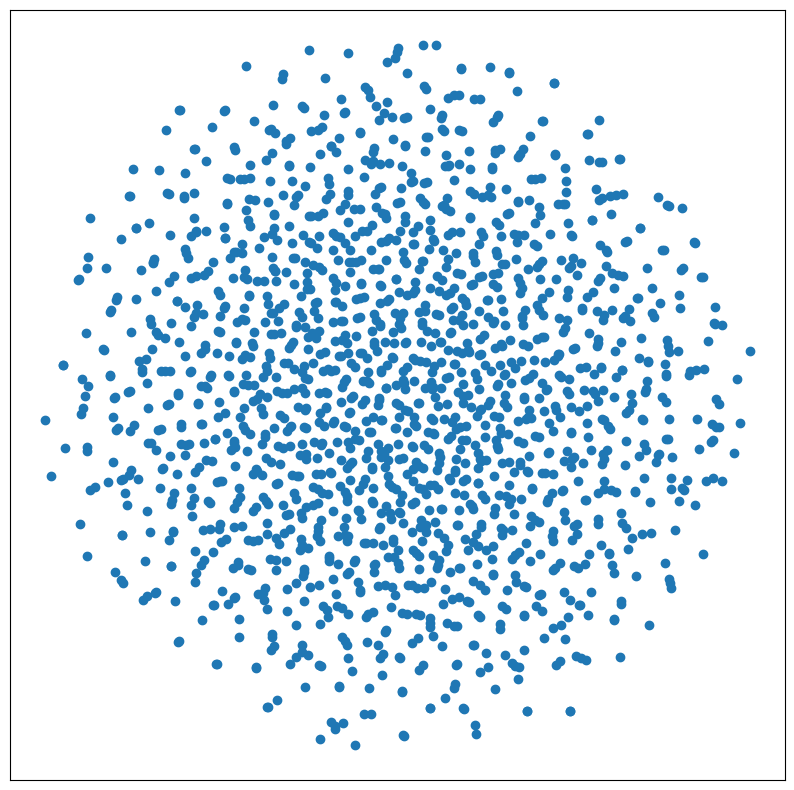

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
plt.scatter(item_tsne[:, 0], item_tsne[:, 1])
plt.xticks(()); plt.yticks(())
plt.show()

In [48]:
# %pip install -q plotly

In [49]:
import plotly.express as px

tsne_df = pd.DataFrame(item_tsne, columns=["tsne_1", "tsne_2"])
tsne_df["item_id"] = np.arange(item_tsne.shape[0])
tsne_df = tsne_df.merge(items.reset_index())

px.scatter(tsne_df, x="tsne_1", y="tsne_2",
           color="popularity",
           hover_data=["item_id", "title", "popularity"])

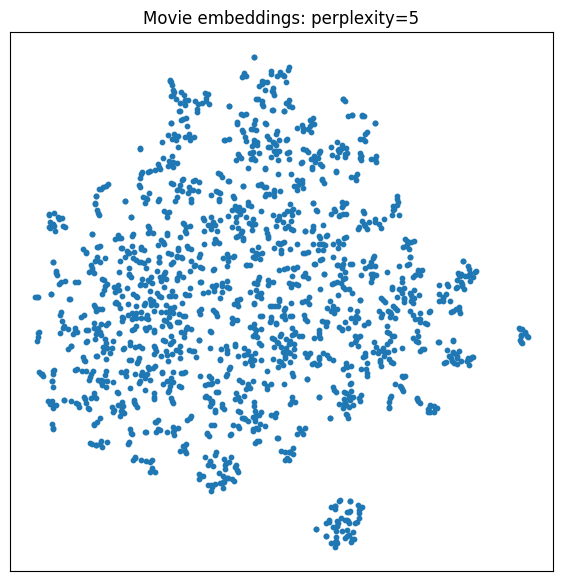

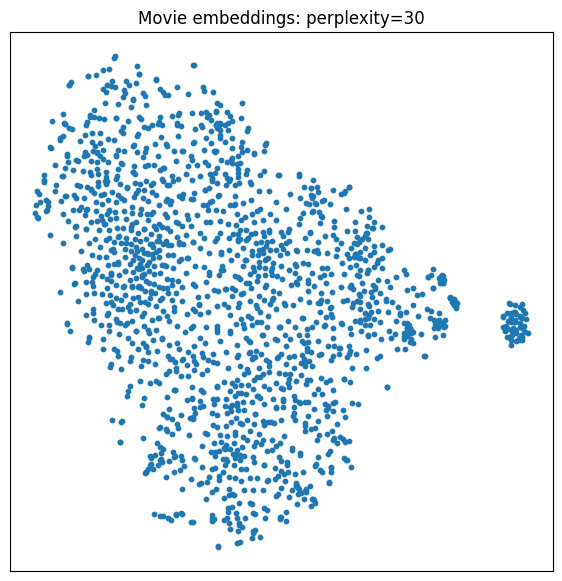

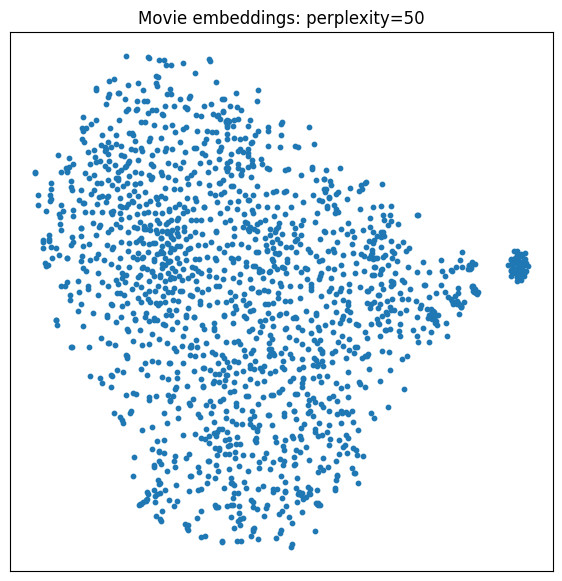

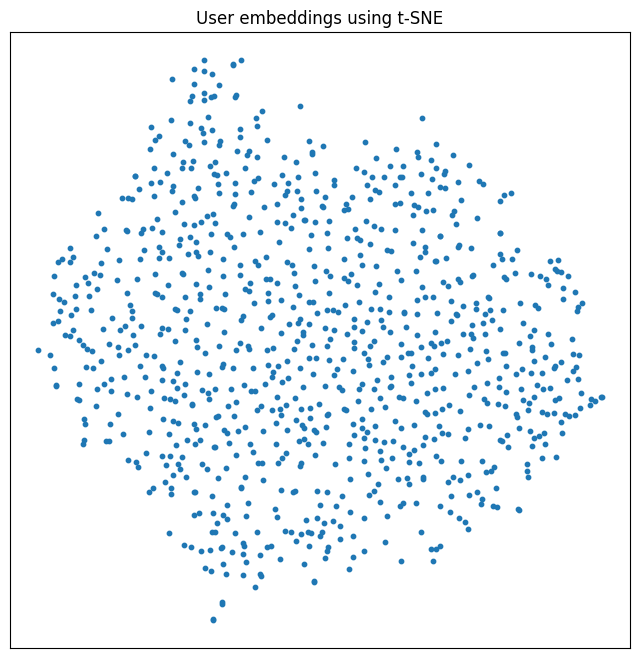

In [103]:
# Compare different t-SNE perplexities for movie embeddings
for perplexity in [5, 30, 50]:
    item_tsne_test = TSNE(
        n_components=2,
        learning_rate="auto",
        init="pca",
        perplexity=perplexity,
        random_state=0
    ).fit_transform(item_embeddings[1:])

    plt.figure(figsize=(7, 7))
    plt.scatter(item_tsne_test[:, 0], item_tsne_test[:, 1], s=10)
    plt.title(f"Movie embeddings: perplexity={perplexity}")
    plt.xticks([])
    plt.yticks([])
    plt.show()

# Visualise user embeddings
user_embeddings = model.get_weights()[0]

user_tsne = TSNE(
    n_components=2,
    learning_rate="auto",
    init="pca",
    perplexity=30,
    random_state=0
).fit_transform(user_embeddings[1:])

plt.figure(figsize=(8, 8))
plt.scatter(user_tsne[:, 0], user_tsne[:, 1], s=10)
plt.title("User embeddings using t-SNE")
plt.xticks([])
plt.yticks([])
plt.show()

Alternatively with [Uniform Manifold Approximation and Projection](https://github.com/lmcinnes/umap):

In [52]:
%pip install umap-learn

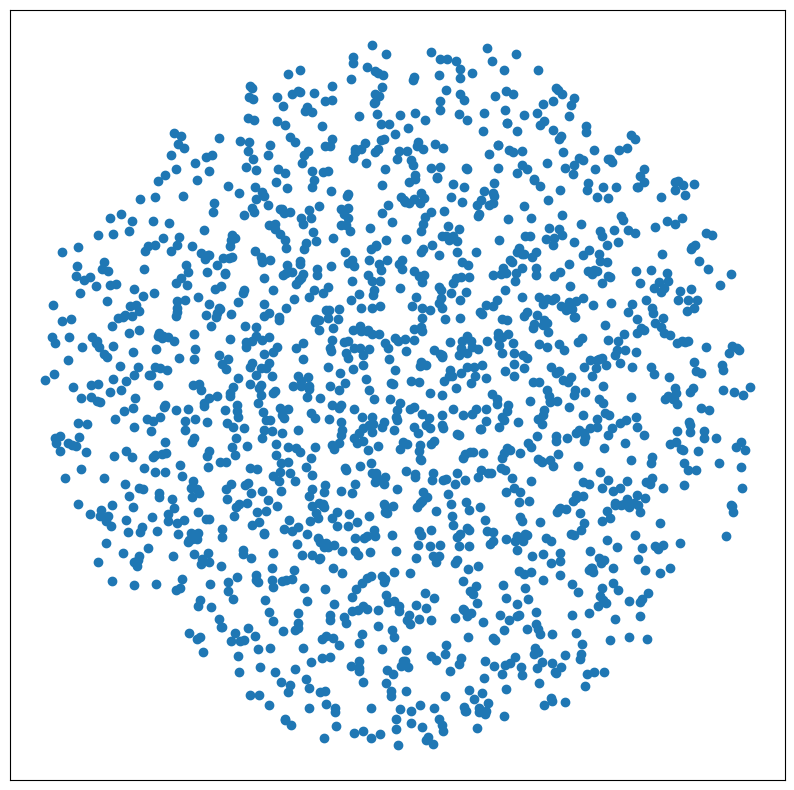

In [53]:
import umap

item_umap = umap.UMAP().fit_transform(item_embeddings)
plt.figure(figsize=(10, 10))
plt.scatter(item_umap[:, 0], item_umap[:, 1]);
plt.xticks(()); plt.yticks(());
plt.show()

## A Deep recommender model

Using a similar framework as previously, the following deep model described in the course was built (with only two fully connected)

<img src="images/rec_archi_2.svg" style="width: 600px;" />

To build this model we will need a new kind of layer:

In [68]:
from keras.layers import Concatenate


### Exercise

- The following code has **4 errors** that prevent it from working correctly. **Correct them and explain** why they are critical.

In [71]:
class DeepRegressionModel(Model):

    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_user_id + 1,  # input length not needed since it is determined when receiving user and movie IDs
                                        name='user_embedding')
        self.item_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_item_id + 1,
                                        name='item_embedding')

        # The following two layers don't have parameters.
        self.flatten = Flatten()
        self.concat = Concatenate()

        self.dropout = Dropout(0.35) # 0.99 will remove all input values, so the model can't learn useful patterns
        self.dense1 = Dense(64, activation="relu")
        self.dense2 = Dense(1)  # Regression model needs only one neuron for per user-movie pair. Ratings are between 1-5 but tanh is ranged between -1 to 1.

    def call(self, inputs, training=False):
        user_inputs = inputs[0]
        item_inputs = inputs[1]

        user_vecs = self.flatten(self.user_embedding(user_inputs))
        item_vecs = self.flatten(self.item_embedding(item_inputs))

        input_vecs = self.concat([user_vecs, item_vecs])

        y = self.dropout(input_vecs, training=training)
        y = self.dense1(y)
        y = self.dense2(y)

        return y

model = DeepRegressionModel(64, max_user_id, max_item_id)
model.compile(optimizer='adam', loss='mse') # mse is for regression, binary cross entropy for categorical data (binary)

initial_train_preds = model.predict([user_id_train, item_id_train])

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


Explanation of the corrections
1. Unnecessary input_length argument: The input_length=1 argument is unnecessary because the input shape can be inferred from the user and movie ID tensors.
2. Dropout rate: A dropout rate of 0.99 drops 99% of activations during training, which makes learning difficult.
3. Output activation: A tanh activation restricts predictions to between -1 and 1, whereas ratings range from 1 to 5. A linear output (Dense(1) with no activation specified) is more suitable for rating regression.
4. Loss function: Binary cross-entropy is designed for binary classification, not continuous rating prediction. MSE or MAE is suitable for regressions tasks.

In [73]:
%%time
history = model.fit([user_id_train, item_id_train], rating_train,
                    batch_size=64, epochs=10, validation_split=0.1,
                    shuffle=True)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 1.7817 - val_loss: 0.9320
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.9184 - val_loss: 0.9020
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8953 - val_loss: 0.8973
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8802 - val_loss: 0.8881
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.8635 - val_loss: 0.8761
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8487 - val_loss: 0.8812
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8349 - val_loss: 0.8689
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.8214 - val_loss: 0.8771
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.8080 - val_loss: 0.8717
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.7979 - val_loss: 0.8648
CPU times: user 52.5 s, sys: 3.01 s, total: 55.5 s
Wall time: 42.5 s


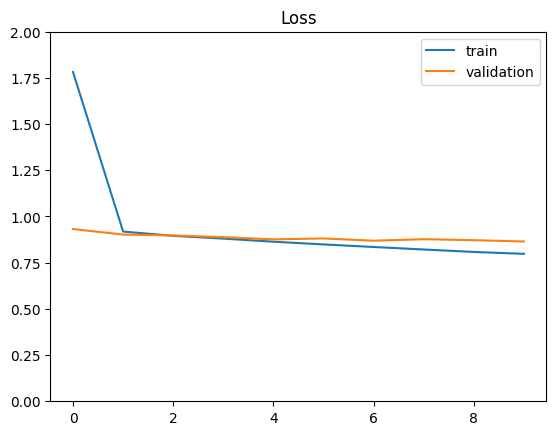

In [74]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.ylim(0, 2)
plt.legend(loc='best')
plt.title('Loss');

In [75]:
train_preds = model.predict([user_id_train, item_id_train])
print("Final train MSE: %0.3f" % mean_squared_error(train_preds, rating_train))
print("Final train MAE: %0.3f" % mean_absolute_error(train_preds, rating_train))

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
Final train MSE: 0.749
Final train MAE: 0.684


In [76]:
test_preds = model.predict([user_id_test, item_id_test])
print("Final test MSE: %0.3f" % mean_squared_error(test_preds, rating_test))
print("Final test MAE: %0.3f" % mean_absolute_error(test_preds, rating_test))

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Final test MSE: 0.862
Final test MAE: 0.736


The performance of this model is not necessarily significantly better than the previous model but you can notice that the gap between train and test is lower, probably thanks to the use of dropout.

Furthermore this model is more flexible in the sense that we can extend it to include metadata for hybrid recsys as we will see in the following.

### Home assignment:
 - Add another layer, compare train/test error.
 - Can you improve the test MAE?
 - Try adding more dropout and change layer sizes.


Manual tuning of so many hyperparameters is tedious. In practice it's better to automate the design of the model using an hyperparameter search tool such as:

- https://keras-team.github.io/keras-tuner/ (Keras specific)
- https://optuna.org/ (any machine learning framework, Keras included)

In [101]:
# Add another hidden layer

class DeeperRegressionModel(Model):

    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(max_user_id + 1, embedding_size)
        self.item_embedding = Embedding(max_item_id + 1, embedding_size)

        self.flatten = Flatten()
        self.concat = Concatenate()

        self.dropout = Dropout(0.3)
        self.dense1 = Dense(64, activation="relu")
        self.dense2 = Dense(32, activation="relu")
        self.dense3 = Dense(1)

    def call(self, inputs, training=False):
        user_inputs, item_inputs = inputs

        user_vec = self.flatten(self.user_embedding(user_inputs))
        item_vec = self.flatten(self.item_embedding(item_inputs))

        x = self.concat([user_vec, item_vec])
        x = self.dropout(x, training=training)
        x = self.dense1(x)
        x = self.dense2(x)
        x = self.dropout(x, training=training)
        x = self.dense3(x)

        return x


# Create and compile the model
deeper_model = DeeperRegressionModel(
    64, max_user_id, max_item_id
)

deeper_model.compile(optimizer="adam", loss="mae")

# Train the model
deeper_history = deeper_model.fit(
    [user_id_train, item_id_train],
    rating_train,
    batch_size=64,
    epochs=10,
    validation_split=0.1,
    shuffle=True
)

# Calculate MAE using the final trained model
deeper_train_preds = deeper_model.predict(
    [user_id_train, item_id_train], verbose=0
).ravel()

deeper_test_preds = deeper_model.predict(
    [user_id_test, item_id_test], verbose=0
).ravel()

deeper_train_mae = mean_absolute_error(
    rating_train, deeper_train_preds
)

deeper_test_mae = mean_absolute_error(
    rating_test, deeper_test_preds
)

print(f"Deeper model train MAE: {deeper_train_mae:.3f}")
print(f"Deeper model validation MAE: {deeper_history.history['val_loss'][-1]:.3f}")
print(f"Deeper model test MAE: {deeper_test_mae:.3f}")

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 1.0139 - val_loss: 0.7657
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.8591 - val_loss: 0.7590
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8263 - val_loss: 0.7497
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.7963 - val_loss: 0.7431
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.7699 - val_loss: 0.7364
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.7554 - val_loss: 0.7369
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.7382 - val_loss: 0.7354
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7246 - val_loss: 0.7372
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7139 - val_loss: 0.7338
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7056 - val_loss: 0.7338
Deeper model train MAE: 0.665
Deeper model validation MAE: 0.734
Deeper model test MAE: 0.730


In [102]:
# Experiment with larger hidden layers and more dropout
class ModifiedDeeperRegressionModel(Model):

    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(max_user_id + 1, embedding_size)
        self.item_embedding = Embedding(max_item_id + 1, embedding_size)

        self.flatten = Flatten()
        self.concat = Concatenate()

        self.dropout = Dropout(0.5)
        self.dense1 = Dense(128, activation="relu")
        self.dense2 = Dense(64, activation="relu")
        self.dense3 = Dense(1)

    def call(self, inputs, training=False):
        user_inputs, item_inputs = inputs

        user_vec = self.flatten(self.user_embedding(user_inputs))
        item_vec = self.flatten(self.item_embedding(item_inputs))

        x = self.concat([user_vec, item_vec])
        x = self.dropout(x, training=training)
        x = self.dense1(x)
        x = self.dense2(x)
        x = self.dropout(x, training=training)
        return self.dense3(x)


modified_model = ModifiedDeeperRegressionModel(
    64, max_user_id, max_item_id
)

modified_model.compile(optimizer="adam", loss="mae")

modified_model.fit(
    [user_id_train, item_id_train],
    rating_train,
    batch_size=64,
    epochs=10,
    validation_split=0.1,
    shuffle=True
)

modified_train_preds = modified_model.predict(
    [user_id_train, item_id_train], verbose=0
).ravel()

modified_test_preds = modified_model.predict(
    [user_id_test, item_id_test], verbose=0
).ravel()

modified_train_mae = mean_absolute_error(
    rating_train, modified_train_preds
)
modified_test_mae = mean_absolute_error(
    rating_test, modified_test_preds
)

print(f"Modified model train MAE: {modified_train_mae:.3f}")
print(f"Modified model test MAE: {modified_test_mae:.3f}")

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 1.0121 - val_loss: 0.8056
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 0.8796 - val_loss: 0.7689
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.8397 - val_loss: 0.7576
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 0.8105 - val_loss: 0.7565
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.7855 - val_loss: 0.7465
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7651 - val_loss: 0.7393
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7517 - val_loss: 0.7422
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7403 - val_loss: 0.7356
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.7337 - val_loss: 0.7341
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7255 - val_loss: 0.7382
Modified model train MAE: 0.692
Modified model test MAE: 0.736


\begin{array}{|l|c|c|c|c|}
\hline
\textbf{Model} & \textbf{Dropout} & \textbf{Hidden Layers} & \textbf{Train MAE} & \textbf{Test MAE} \\
\hline
\text{Original model} & 0.35 & 64 & 0.684 & 0.736 \\
\hline
\text{Deeper model} & 0.3 & 64 \to 32 & \text{0.665} & \text{0.730} \\
\hline
\text{Modified model} & 0.5 & 128 \to 64 & \text{0.692} & \text{0.736} \\
\hline
\end{array}

## Using item metadata in the model

Using a similar framework as previously, we will build another deep model that can also leverage additional metadata. The resulting system is therefore an **Hybrid Recommender System** that does both **Collaborative Filtering** and **Content-based recommendations**.

<img src="images/rec_archi_3.svg" style="width: 600px;" />


In [77]:
from sklearn.preprocessing import QuantileTransformer

meta_columns = ['popularity', 'release_year']

scaler = QuantileTransformer()
item_meta_train = scaler.fit_transform(ratings_train[meta_columns])
item_meta_test = scaler.transform(ratings_test[meta_columns])

In [90]:
class HybridModel(Model):

    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_user_id + 1,
                                        input_length=1,
                                        name='user_embedding')
        self.item_embedding = Embedding(output_dim=embedding_size,
                                        input_dim=max_item_id + 1,
                                        input_length=1,
                                        name='item_embedding')

        # The following two layers don't have parameters.
        self.flatten = Flatten()
        self.concat = Concatenate()

        self.dense1 = Dense(64, activation="relu")
        self.dropout = Dropout(0.3)
        self.dense2 = Dense(64, activation='relu')
        self.dense3 = Dense(1)

    def call(self, inputs, training=False):
        user_inputs = inputs[0]
        item_inputs = inputs[1]
        meta_inputs = inputs[2]

        user_vecs = self.flatten(self.user_embedding(user_inputs))
        user_vecs = self.dropout(user_vecs, training=training)

        item_vecs = self.flatten(self.item_embedding(item_inputs))
        item_vecs = self.dropout(item_vecs, training=training)

        input_vecs = self.concat([user_vecs, item_vecs, meta_inputs])

        y = self.dense1(input_vecs)
        y = self.dropout(y, training=training)
        y = self.dense2(y)
        y = self.dropout(y, training=training)
        y = self.dense3(y)
        return y

model = HybridModel(64, max_user_id, max_item_id)
model.compile(optimizer='adam', loss='mae')

initial_train_preds = model.predict([user_id_train,
                                     item_id_train,
                                     item_meta_train])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning:

Argument `input_length` is deprecated. Just remove it.



2500/2500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step


In [91]:
%%time
history = model.fit([user_id_train, item_id_train, item_meta_train],
                    rating_train,
                    batch_size=64, epochs=10, validation_split=0.1,
                    shuffle=True)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.9760 - val_loss: 0.7709
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.8208 - val_loss: 0.7479
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7953 - val_loss: 0.7439
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7774 - val_loss: 0.7315
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7633 - val_loss: 0.7288
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7531 - val_loss: 0.7271
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7413 - val_loss: 0.7317
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.7303 - val_loss: 0.7248
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7226 - val_loss: 0.7237
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.7146 - val_loss: 0.7209
CPU times: user 1min 2s, sys: 3.15 s, total: 1min 5s
Wall time: 53.1 s


In [92]:
test_preds = model.predict([user_id_test, item_id_test, item_meta_test])
print("Final test MSE: %0.3f" % mean_squared_error(test_preds, rating_test))
print("Final test MAE: %0.3f" % mean_absolute_error(test_preds, rating_test))

625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Final test MSE: 0.871
Final test MAE: 0.721


The additional metadata seems to improve the predictive power of the model a bit but this should be re-run several times to see the impact of the random initialization of the model.


### A recommendation function for a given user

Once the model is trained, the system can be used to recommend a few items for a user, that he/she hasn't already seen:
- we use the `model.predict` to compute the ratings a user would have given to all items
- we build a reco function that sorts these items and exclude those the user has already seen

In [93]:
def recommend(user_id, top_n=10):
    item_ids = range(1, max_item_id)
    seen_mask = all_ratings["user_id"] == user_id
    seen_movies = set(all_ratings[seen_mask]["item_id"])
    item_ids = list(filter(lambda x: x not in seen_movies, item_ids))

    print("User %d has seen %d movies, including:" % (user_id, len(seen_movies)))
    for title in all_ratings[seen_mask].nlargest(20, 'popularity')['title']:
        print("   ", title)
    print("Computing ratings for %d other movies:" % len(item_ids))

    item_ids = np.array(item_ids)
    user_ids = np.zeros_like(item_ids)
    user_ids[:] = user_id
    items_meta = scaler.transform(indexed_items[meta_columns].loc[item_ids])

    rating_preds = model.predict([user_ids, item_ids, items_meta])

    item_ids = np.argsort(rating_preds[:, 0])[::-1].tolist()
    rec_items = item_ids[:top_n]
    return [(items["title"][movie], rating_preds[movie][0])
            for movie in rec_items]

In [94]:
for title, pred_rating in recommend(5):
    print("    %0.1f: %s" % (pred_rating, title))

User 5 has seen 175 movies, including:
    Star Wars (1977)
    Fargo (1996)
    Return of the Jedi (1983)
    Toy Story (1995)
    Independence Day (ID4) (1996)
    Raiders of the Lost Ark (1981)
    Silence of the Lambs, The (1991)
    Empire Strikes Back, The (1980)
    Star Trek: First Contact (1996)
    Back to the Future (1985)
    Mission: Impossible (1996)
    Fugitive, The (1993)
    Indiana Jones and the Last Crusade (1989)
    Willy Wonka and the Chocolate Factory (1971)
    Princess Bride, The (1987)
    Forrest Gump (1994)
    Monty Python and the Holy Grail (1974)
    Men in Black (1997)
    E.T. the Extra-Terrestrial (1982)
    Birdcage, The (1996)
Computing ratings for 1506 other movies:
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
    4.9: August (1996)
    4.8: Boys of St. Vincent, The (1993)
    4.6: Search for One-eye Jimmy, The (1996)
    4.6: Up in Smoke (1978)
    4.6: Boogie Nights (1997)
    4.6: Ref, The (1994)
    4.5: Raising Arizona (1987)
    4.5: Romy and Miche

### Home assignment: Predicting ratings as a classification problem

In this dataset, the ratings all belong to a finite set of possible values:

In [95]:
import numpy as np

np.unique(rating_train)

array([1, 2, 3, 4, 5])

Maybe we can help the model by forcing it to predict those values by treating the problem as a multiclassification problem. The only required changes are:

- setting the final layer to output class membership probabities using a softmax activation with 5 outputs;
- optimize the categorical cross-entropy classification loss instead of a regression loss such as MSE or MAE.

In [96]:
# Verify your answer from a tutor.

In [98]:
class ClassificationModel(Model):

    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()

        self.user_embedding = Embedding(max_user_id + 1, embedding_size)
        self.item_embedding = Embedding(max_item_id + 1, embedding_size)

        self.flatten = Flatten()
        self.concat = Concatenate()
        self.dropout = Dropout(0.3)

        self.dense1 = Dense(64, activation="relu")
        self.output_layer = Dense(5, activation="softmax")

    def call(self, inputs, training=False):
        user_inputs, item_inputs = inputs

        user_vec = self.flatten(self.user_embedding(user_inputs))
        item_vec = self.flatten(self.item_embedding(item_inputs))

        x = self.concat([user_vec, item_vec])
        x = self.dropout(x, training=training)
        x = self.dense1(x)
        return self.output_layer(x)

In [99]:
# convert ratings (1–5) to class indices (0–4)
rating_train_class = rating_train.astype(int) - 1
rating_test_class = rating_test.astype(int) - 1

classification_model = ClassificationModel(
    64, max_user_id, max_item_id
)

classification_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

classification_history = classification_model.fit(
    [user_id_train, item_id_train],
    rating_train_class,
    batch_size=64,
    epochs=10,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.4097 - loss: 1.3257 - val_accuracy: 0.4466 - val_loss: 1.2581
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.4568 - loss: 1.2295 - val_accuracy: 0.4462 - val_loss: 1.2467
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4660 - loss: 1.2015 - val_accuracy: 0.4430 - val_loss: 1.2471
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4766 - loss: 1.1830 - val_accuracy: 0.4484 - val_loss: 1.2457
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.4858 - loss: 1.1679 - val_accuracy: 0.4484 - val_loss: 1.2446
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.4914 - loss: 1.1553 - val_accuracy: 0.4502 - val_loss: 1.2483
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.4976 - loss: 1.1431 - val_accuracy: 0.4501 - val_loss: 1.2540
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5008 - loss: 1.1324

In [100]:
probs = classification_model.predict(
    [user_id_test, item_id_test], verbose=0
)

# convert predicted classes (0–4) back to ratings (1–5)
predicted_ratings = np.argmax(probs, axis=1) + 1

print("Test accuracy:",
      np.mean(np.argmax(probs, axis=1) == rating_test_class))

print("Test MAE:",
      mean_absolute_error(rating_test, predicted_ratings))

print("Test MSE:",
      mean_squared_error(rating_test, predicted_ratings))

Test accuracy: 0.4445
Test MAE: 0.7342
Test MSE: 1.1856
